# Лабораторная работа 1: Регрессия и метод главных компонент

---

## Цель работы
Изучение основ линейной регрессии, построение простейших моделей регрессии, проведение обучения модели на реальных данных и оценка её качества.


## Постановка задачи
Провести обучение модели линейной регрессии на датасете с Kaggle.

1. Загрузить датасет из репозитория (например, kaggle.com или аналогичных платформ).
2. Подготовить данные: провести первичный анализ, визуализировать распределение признаков и целевой переменной. 
3. Провести предобработку данных: удалить пропущенные значения, закодировать категориальные переменные (опционально).
4. Построить матрицу корреляций. Сделать выводы о наличии мультиколлинеарности (расчет VIF-коэффициента).
5. Построить регрессионные модели (линейная, лассо и гребневая). Если целевая переменная - категориальная, то исследовать логистическую регрессию. Разделить на тренировочную и тестовую выборки (80/20 или 70/30). Использовать кросс-валидацию. Оценить качество построенной модели с помощью метрик: RMSE (Root Mean Square Error), R² (коэффициент детерминации) и MAPE (Mean Absolute Percentage Error).
6. Построить график остатков моделей (добавить горизонтальную линию на уровне 0) и исследовать структуру остатков на предмет гомоскедастичности или гетероскедастичности.
7. Устранить мультиколлинеарность и снизить размерность признаков с помощью метода главных компонент (PCA). Перед проведением PCA провести стандартизацию данных.
8. Повторить шаг 5 (линейная, лассо и гребневая регрессия), но использовать в качестве признаков не исходные данные, а главные компоненты. Сравнить метрики качества (RMSE, R² и MAPE) моделей, обученных на исходных данных и на главных компонентах.


## Описание датасета

Concrete Compressive Strength - Прочность бетона на сжатие (https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength)

Датасет включает 8 факторов и 1 целевую переменную.

Свойства:
1. Цемент - количество цемента ($\text{кг/м}^3$)
2. Доменный шлак - количество доменного шлака ($\text{кг/м}^3$)
3. Летучая зола - количество летучей золы ($\text{кг/м}^3$)
4. Вода - количество воды ($\text{кг/м}^3$)
5. Пластификатор - количество пластифицирующей добавки ($\text{кг/м}^3$)
6. Крупный заполнитель - количество щебня/гравия ($\text{кг/м}^3$)
7. Мелкий заполнитель - количество песка ($\text{кг/м}^3$)
8. Возраст - время твердения бетона в днях (от 1 до 365 суток)

Целевая переменная:  
9. Прочность бетона на сжатие - непрерывная числовая величина, измеряемая в Мегапаскалях (МПа)


In [ ]:
import os
import sys
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

from ucimlrepo import fetch_ucirepo
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error

print("1. Подготовка данных")
concrete_compressive_strength = fetch_ucirepo(id=165)

X_raw = concrete_compressive_strength.data.features
y_raw = concrete_compressive_strength.data.targets

df_raw = pd.concat([X_raw, y_raw], axis=1)
print(f"Размерность датасета: {df_raw.shape[0]} строк, {df_raw.shape[1]} столбцов\n")

col_map = {
    df_raw.columns[0]: 'Цемент (кг/м³)',
     df_raw.columns[1]: 'Доменный шлак (кг/м³)',
    df_raw.columns[2]: 'Летучая зола (кг/м³)',
    df_raw.columns[3]: 'Вода (кг/м³)',
    df_raw.columns[4]: 'Пластификатор (кг/м³)',
    df_raw.columns[5]: 'Крупный заполнитель (кг/м³)',
    df_raw.columns[6]: 'Мелкий заполнитель (кг/м³)',
    df_raw.columns[7]: 'Возраст (дни)',
    df_raw.columns[8]: 'Прочность на сжатие (МПа)'
}
df = df_raw.rename(columns=col_map)

print("Первая строка датасета:")
print(df.head(1).to_string())

duplicates_count = df.duplicated().sum()
if duplicates_count > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"\nУдалено дубликатов: {duplicates_count}. Новый размер: {df.shape}")

df['Водоцементное отношение (W/C)'] = df['Вода (кг/м³)'] / (df['Цемент (кг/м³)'] + 1e-5)
df['Лог(Возраст)'] = np.log1p(df['Возраст (дни)'])

1. Подготовка данных
Размерность датасета: 1030 строк, 9 столбцов

Первая строка датасета:
   Цемент (кг/м³)  Доменный шлак (кг/м³)  Летучая зола (кг/м³)  Вода (кг/м³)  Пластификатор (кг/м³)  Крупный заполнитель (кг/м³)  Мелкий заполнитель (кг/м³)  Возраст (дни)  Прочность на сжатие (МПа)
0           540.0                    0.0                   0.0         162.0                    2.5                       1040.0                       676.0             28                      79.99

Удалено дубликатов: 25. Новый размер: (1005, 9)


В предварительной подготовке было посчитана размерность, продемонстрированна строка пример, а также проведенна очистка от дубликатов. Информация про отстуствие пустых строк была известна при выборе датасета, поэтому в дополнительном анализе не нуждается.


2. Описательная статистика
Признак                    Цемент (кг/м³)  Доменный шлак (кг/м³)  Летучая зола (кг/м³)  Вода (кг/м³)  Пластификатор (кг/м³)  Крупный заполнитель (кг/м³)  Мелкий заполнитель (кг/м³)  Возраст (дни)  Прочность на сжатие (МПа)  Водоцементное отношение (W/C)  Лог(Возраст)
Среднее                          278.6313                72.0435               55.5363      182.0753                 6.0332                     974.3768                    772.6883        45.8567                    35.2504                         0.7562        3.2450
Стандартная ошибка                 3.2914                 2.7182                2.0254        0.6731                 0.1867                       2.4472                      2.5343         2.0104                     0.5137                         0.0099        0.0350
Медиана                          265.0000                20.0000                0.0000      185.7000                 6.1000                     968.0000                

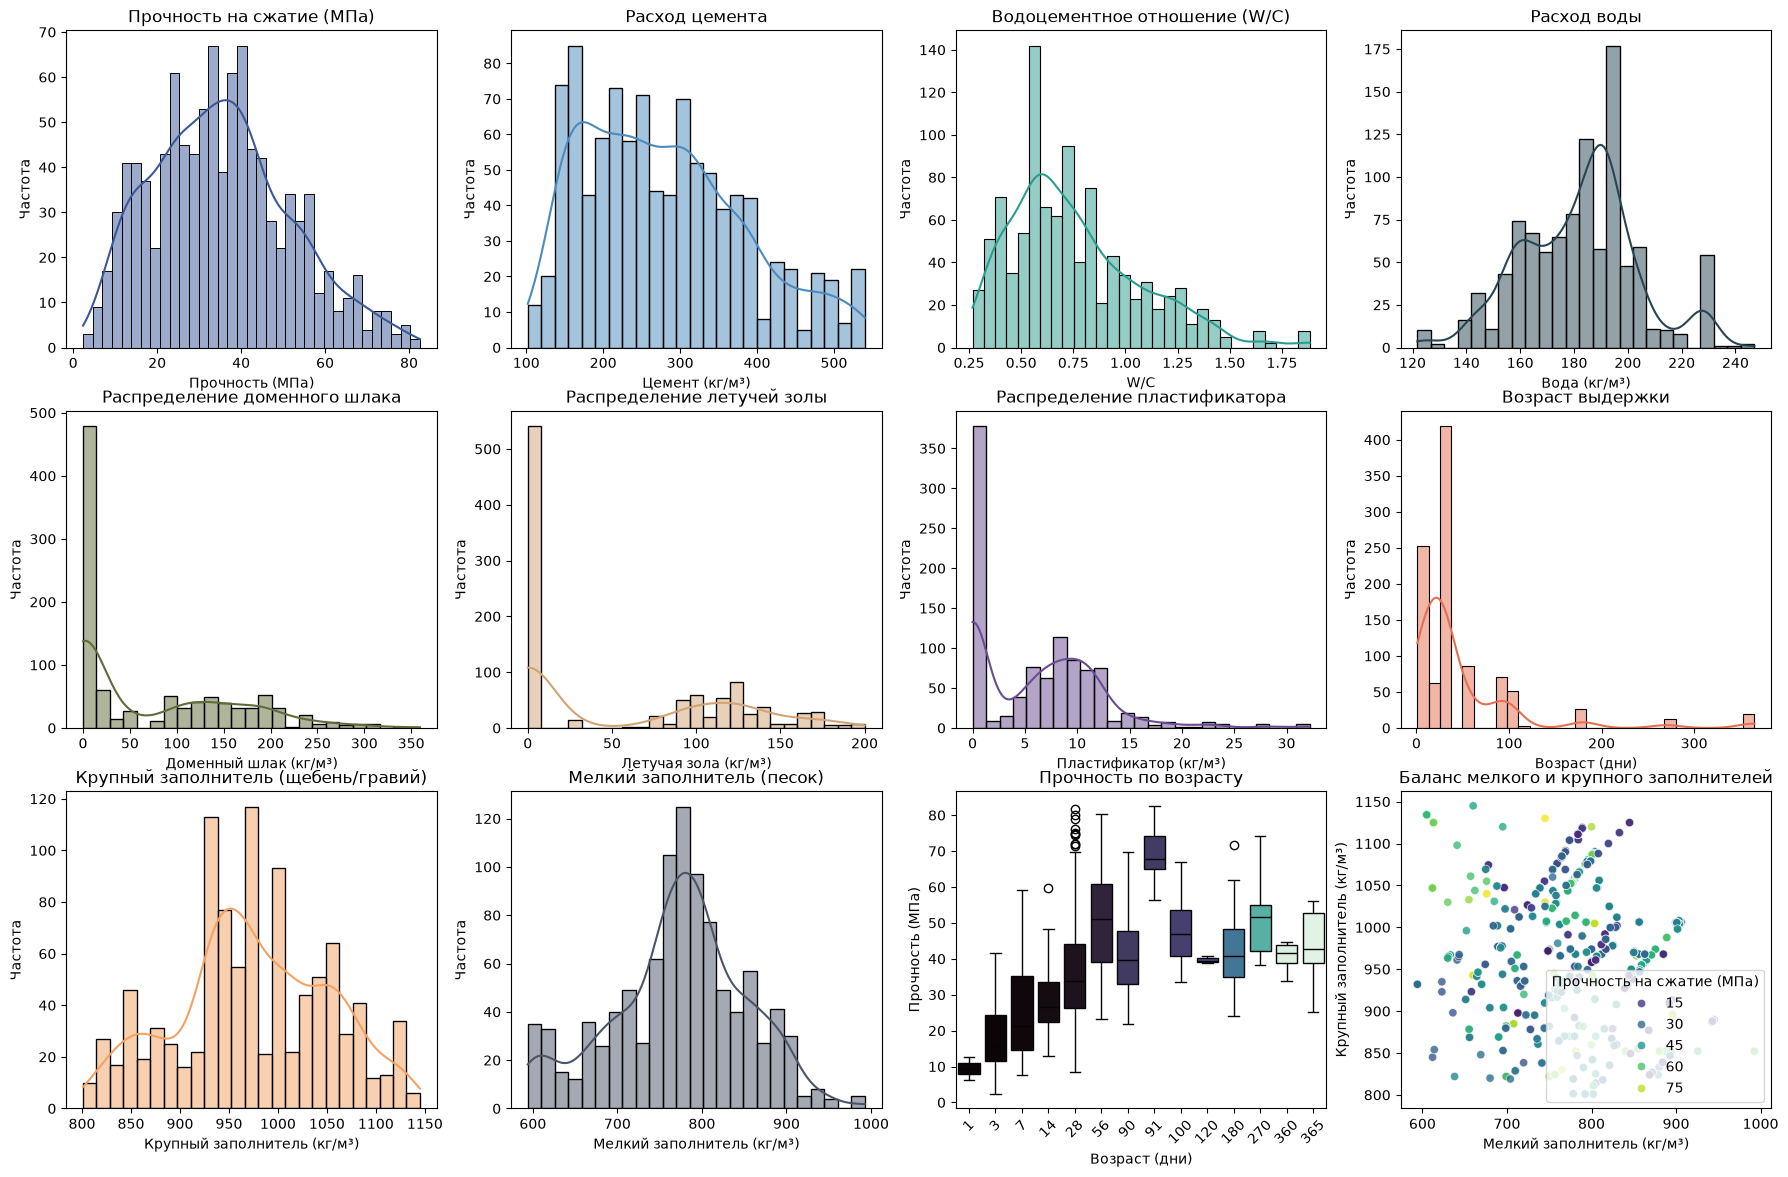

In [13]:
def calculate_excel_descriptive_stats(df_num):
    metrics = []
    
    for col in df_num.columns:
        series = df_num[col].dropna()
        n = len(series)
        
        mean_val = series.mean()
        std_val = series.std(ddof=1)
        sem_val = stats.sem(series)
        median_val = series.median()
        
        mode_series = series.mode()
        mode_val = mode_series.iloc[0] if not mode_series.empty else np.nan
        
        var_val = series.var(ddof=1)
        kurt_val = series.kurtosis()
        skew_val = series.skew()
        
        min_val = series.min()
        max_val = series.max()
        range_val = max_val - min_val
        sum_val = series.sum()
        
        if n > 1:
            confidence_val = stats.t.ppf((1 + 0.95) / 2., n - 1) * (std_val / np.sqrt(n))
        else:
            confidence_val = np.nan
            
        metrics.append({
            'Признак': col,
            'Среднее': mean_val,
            'Стандартная ошибка': sem_val,
            'Медиана': median_val,
            'Мода': mode_val,
            'Стандартное отклонение': std_val,
            'Дисперсия выборки': var_val,
            'Эксцесс': kurt_val,
            'Асимметричность': skew_val,
            'Интервал (Размах)': range_val,
            'Минимум': min_val,
            'Максимум': max_val,
            'Сумма': sum_val,
            'Счет': n,
            'Уровень надежности(95,0%)': confidence_val
        })
        
    return pd.DataFrame(metrics).set_index('Признак').T

print("\n2. Описательная статистика")
stats_table = calculate_excel_descriptive_stats(df)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
print(stats_table.round(4).to_string())

c_main = '#3B5998'      
c_secondary = '#4B8BBE' 
c_teal = '#2A9D8F'      
c_accent = '#E76F51'    
c_purple = '#6A4C93'    
c_dark = '#264653'     
c_olive = '#606C38'     
c_amber = '#D4A373'     
c_coral = '#F4A261'     
c_slate = '#4A5568'     

fig, axes = plt.subplots(3, 4, figsize=(22, 14))

sns.histplot(df['Прочность на сжатие (МПа)'], kde=True, ax=axes[0, 0], color=c_main, bins=35, edgecolor='black')
axes[0, 0].set_title('Прочность на сжатие (МПа)')
axes[0, 0].set_xlabel('Прочность (МПа)')
axes[0, 0].set_ylabel('Частота')

sns.histplot(df['Цемент (кг/м³)'], kde=True, ax=axes[0, 1], color=c_secondary, bins=25, edgecolor='black')
axes[0, 1].set_title('Расход цемента')
axes[0, 1].set_xlabel('Цемент (кг/м³)')
axes[0, 1].set_ylabel('Частота')

sns.histplot(df['Водоцементное отношение (W/C)'], kde=True, ax=axes[0, 2], color=c_teal, bins=30, edgecolor='black')
axes[0, 2].set_title('Водоцементное отношение (W/C)')
axes[0, 2].set_xlabel('W/C')
axes[0, 2].set_ylabel('Частота')

sns.histplot(df['Вода (кг/м³)'], kde=True, ax=axes[0, 3], color=c_dark, bins=25, edgecolor='black')
axes[0, 3].set_title('Расход воды')
axes[0, 3].set_xlabel('Вода (кг/м³)')
axes[0, 3].set_ylabel('Частота')

sns.histplot(df['Доменный шлак (кг/м³)'], kde=True, ax=axes[1, 0], color=c_olive, bins=25, edgecolor='black')
axes[1, 0].set_title('Распределение доменного шлака')
axes[1, 0].set_xlabel('Доменный шлак (кг/м³)')
axes[1, 0].set_ylabel('Частота')

sns.histplot(df['Летучая зола (кг/м³)'], kde=True, ax=axes[1, 1], color=c_amber, bins=25, edgecolor='black')
axes[1, 1].set_title('Распределение летучей золы')
axes[1, 1].set_xlabel('Летучая зола (кг/м³)')
axes[1, 1].set_ylabel('Частота')

sns.histplot(df['Пластификатор (кг/м³)'], kde=True, ax=axes[1, 2], color=c_purple, bins=25, edgecolor='black')
axes[1, 2].set_title('Распределение пластификатора')
axes[1, 2].set_xlabel('Пластификатор (кг/м³)')
axes[1, 2].set_ylabel('Частота')

sns.histplot(df['Возраст (дни)'], kde=True, ax=axes[1, 3], color=c_accent, bins=30, edgecolor='black')
axes[1, 3].set_title('Возраст выдержки')
axes[1, 3].set_xlabel('Возраст (дни)')
axes[1, 3].set_ylabel('Частота')

sns.histplot(df['Крупный заполнитель (кг/м³)'], kde=True, ax=axes[2, 0], color=c_coral, bins=25, edgecolor='black')
axes[2, 0].set_title('Крупный заполнитель (щебень/гравий)')
axes[2, 0].set_xlabel('Крупный заполнитель (кг/м³)')
axes[2, 0].set_ylabel('Частота')

sns.histplot(df['Мелкий заполнитель (кг/м³)'], kde=True, ax=axes[2, 1], color=c_slate, bins=25, edgecolor='black')
axes[2, 1].set_title('Мелкий заполнитель (песок)')
axes[2, 1].set_xlabel('Мелкий заполнитель (кг/м³)')
axes[2, 1].set_ylabel('Частота')

sns.boxplot(data=df, x='Возраст (дни)', y='Прочность на сжатие (МПа)', hue='Возраст (дни)', ax=axes[2, 2], palette='mako', legend=False)
axes[2, 2].set_title('Прочность по возрасту')
axes[2, 2].set_xlabel('Возраст (дни)')
axes[2, 2].set_ylabel('Прочность (МПа)')
axes[2, 2].tick_params(axis='x', rotation=45)

sns.scatterplot(data=df, x='Мелкий заполнитель (кг/м³)', y='Крупный заполнитель (кг/м³)', hue='Прочность на сжатие (МПа)',palette='viridis', alpha=0.8, ax=axes[2, 3])
axes[2, 3].set_title('Баланс мелкого и крупного заполнителей')
axes[2, 3].set_xlabel('Мелкий заполнитель (кг/м³)')
axes[2, 3].set_ylabel('Крупный заполнитель (кг/м³)');

Описательная статистика представляет собой классический набор метрик из Excel.
- Среднее - среднестатистическое значение
- Стандартная ошибка - статистическая погрешность измерения среднего значения выборки
- Медианна - значение, делящее отсортированный ряд ровно пополам (50%-й квантиль)
- Мода - наиболее часто встречающееся значение в ряду наблюдений
- Стандартное отклонение - абсолютная мера разброса значений вокруг среднего в исходных единицах
- Дисперсия выборки - мера рассеяния значений, равная квадрату стандартного отклонения
- Эксцесс - мера островершинности распределения и тяжести его «хвостов»
- Асимметричность - мера скошенности (несимметричности) распределения относительно центра
- Интервал (Размах) - полная ширина диапазона варьирования данных
- Минимум - наименьшее зафиксированное значение в выборке
- Максимум - наибольшее зафиксированное значение в выборке
- Счет - количество валидных (непустых) наблюдений
- Уровень надежности (95.0%) - полуширина 95%-го доверительного интервала для математического ожидания




Комментарии к графикам:


- Прочность на сжатие (МПа)  
Распределение целевого признака близко к умеренно-симметричному с небольшой правой асимметрией. Основная масса образцов демонстрирует прочность в диапазоне 20–50 МПа с пиком в районе 35–40 МПа. Присутствуют единичные высокопрочные составы (до 80 МПа).   


- Расход цемента (кг/м³)  
Показывает равномерно-бимодальный характер расхода цемента. Основной массив данных сосредоточен в пределах 150–350 кг/м³ с постепенным спадом к 500 кг/м³.   


- Водоцементное отношение (W/C)  
Распределение умеренно асимметрично вправо. Наибольшая концентрация замеров наблюдается в диапазоне $W/C = 0.4\dots0.7$, что является технологическим стандартом. Наличие хвоста до $1.8$ указывает на присутствие низкомаркировочных или экспериментальных составов.   


- Расход воды (кг/м³)  
Имеет ярко выраженный острый пик около значения 190–200 кг/м³, что соответствует типовому расходу воды для затворения стандартных бетонных смесей. Дополнительный небольшой пик в районе 220–230 кг/м³ отражает высокоподвижные составы.


- Распределение доменного шлака (кг/м³)  
Отмечается доминирующий пик в районе 0 кг/м³, показывающий, что в большинстве замеров доменный шлак не использовался. Для составов с добавкой расход распределен относительно равномерно от 50 до 200 кг/м³.  


- Распределение летучей золы (кг/м³) 
Аналогично шлаку, наблюдается высокий столб в нуле, отражающий отсутствие добавки в большей части рецептур. При добавлении золы её расход чаще всего составляет 100–140 кг/м³.   
 
 
- Распределение пластификатора (кг/м³)  
Значительная часть рецептур не содержит суперпластификатор (высокий пик в 0). При применении пластификатора его дозировка сгруппирована в диапазоне 6–12 кг/м³.   


- Возраст выдержки (дни)  
Наблюдается экстремальная правосторонняя асимметрия. Абсолютное большинство испытаний выполнено в стандартные контрольные сроки — 28 дней (самый высокий столбец), а также 7 и 14 дней. Испытания на длительных сроках (до 365 дней) единичны.


- Крупный заполнитель (щебень/гравий) (кг/м³)  
Имеет двугорбое (бимодальное) распределение с основными концентрациями около 950 кг/м³ и 1050 кг/м³, что обусловлено применением различных фракций и типов крупного заполнителя.   


- Мелкий заполнитель (песок) (кг/м³)  
Близкое к одновершинному распределению с четким максимумом около 750–800 кг/м³, что отражает оптимальное наполнение растворной части бетона.   


- Прочность по возрасту  
Наглядно иллюстрирует динамику набора прочности во времени: на ранних сроках (1–7 дней) наблюдается быстрый рост прочности. К 28–56 дням медиана прочности выходит на плато около 40–50 МПа. На сроках от 90 до 365 дней рост прочности замедляется, но стабильно сохраняется.   


- Баланс мелкого и крупного заполнителей  
Показывает соотношение песка и щебня. Цвет точек отражает прочность на сжатие (от фиолетового — низкая, до желтого — высокая). Максимальная прочность наблюдается при сбалансированном соотношении заполнителей (в центре облака точек) в сочетании с оптимальным W/C и возрастом

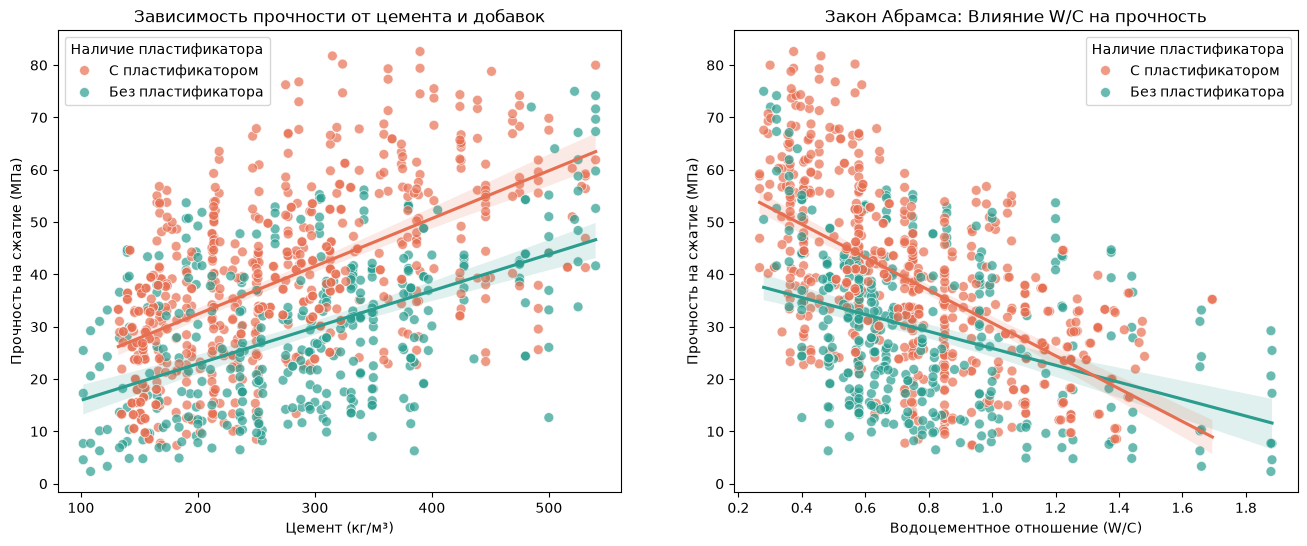

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

df['Наличие пластификатора'] = np.where(df['Пластификатор (кг/м³)'] > 0, 'С пластификатором', 'Без пластификатора')
palette_plast = {'Без пластификатора': c_teal, 'С пластификатором': c_accent}

sns.scatterplot(data=df, x='Цемент (кг/м³)', y='Прочность на сжатие (МПа)', hue='Наличие пластификатора', palette=palette_plast, alpha=0.7, s=50, ax=axes[0])
sns.regplot(data=df[df['Наличие пластификатора'] == 'Без пластификатора'], x='Цемент (кг/м³)', y='Прочность на сжатие (МПа)', scatter=False, ax=axes[0], color=c_teal)
sns.regplot(data=df[df['Наличие пластификатора'] == 'С пластификатором'], x='Цемент (кг/м³)', y='Прочность на сжатие (МПа)', scatter=False, ax=axes[0], color=c_accent)
axes[0].set_title('Зависимость прочности от цемента и добавок')
axes[0].set_xlabel('Цемент (кг/м³)')
axes[0].set_ylabel('Прочность на сжатие (МПа)')

sns.scatterplot(data=df, x='Водоцементное отношение (W/C)', y='Прочность на сжатие (МПа)', hue='Наличие пластификатора',
                    palette=palette_plast, alpha=0.7, s=50, ax=axes[1])
sns.regplot(data=df[df['Наличие пластификатора'] == 'Без пластификатора'], x='Водоцементное отношение (W/C)', y='Прочность на сжатие (МПа)', scatter=False, ax=axes[1], color=c_teal)
sns.regplot(data=df[df['Наличие пластификатора'] == 'С пластификатором'], x='Водоцементное отношение (W/C)', y='Прочность на сжатие (МПа)', scatter=False, ax=axes[1], color=c_accent)
axes[1].set_title('Закон Абрамса: Влияние W/C на прочность')
axes[1].set_xlabel('Водоцементное отношение (W/C)')
axes[1].set_ylabel('Прочность на сжатие (МПа)');

В дополнение к классическим графикам были добавлены графики зависимости наличия пластификатора для проверки технологической синергии: пластификатор нужен не только для увеличения прочности, сколько позволяет безопасно снизить водоцементное отношение ($W/C$) до низких значений без потери укладываемости смеси.


- Зависимость прочности от цемента и добавок  
При одинаковом расходе цемента (например, 300 кг/м³) использование пластификатора позволяет получить прочность в среднем на 10–15 МПа выше. Это происходит за счет того, что пластификатор снижает водопотребность смеси без потери её подвижности.


- Закон Абрамса: Влияние W/C на прочность  
При значении W/C выше 1.4 влияние пластификатора практически нивелируется (линии регрессии пересекаются), так как избыток воды в смеси создает высокую пористость и критически снижает прочностные характеристики независимо от добавок.


3. Корреляция признаков с целевой переменной (Прочность на сжатие):
Лог(Возраст)                     0.560
Цемент (кг/м³)                   0.488
Пластификатор (кг/м³)            0.344
Возраст (дни)                    0.337
Доменный шлак (кг/м³)            0.103
Летучая зола (кг/м³)            -0.081
Крупный заполнитель (кг/м³)     -0.145
Мелкий заполнитель (кг/м³)      -0.186
Вода (кг/м³)                    -0.270
Водоцементное отношение (W/C)   -0.489


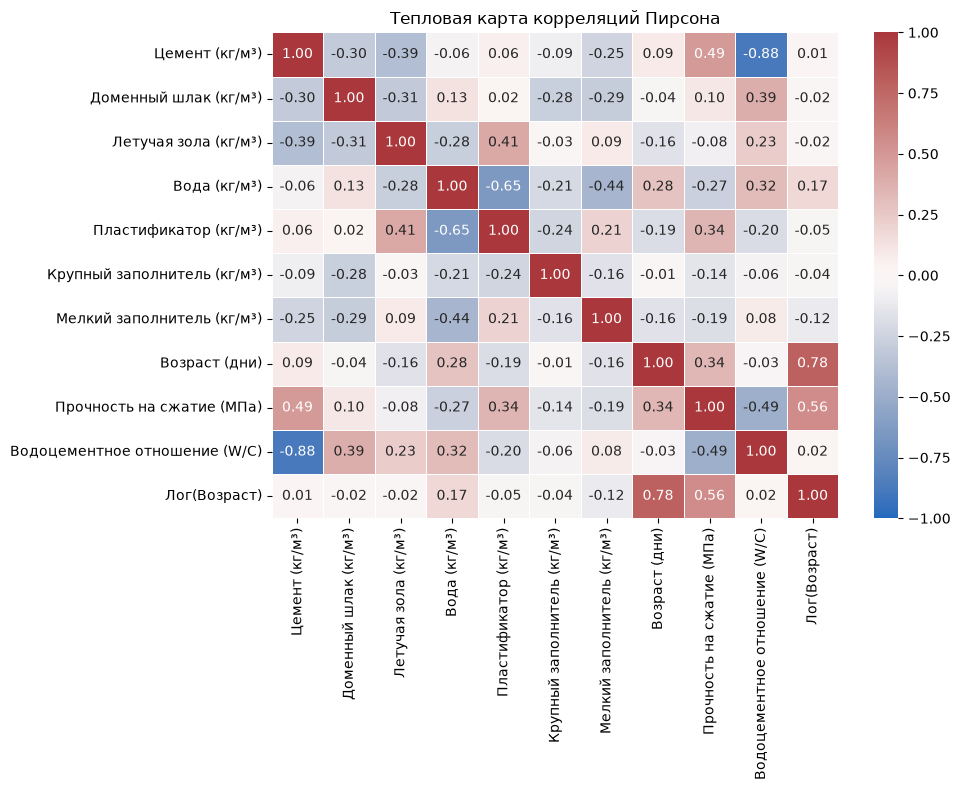

In [24]:
df_analysis = df.drop(columns=['Наличие пластификатора'])

corr_matrix = df_analysis.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='vlag', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Тепловая карта корреляций Пирсона')
plt.tight_layout()

target_col = 'Прочность на сжатие (МПа)'
concrete_corr = corr_matrix[target_col].drop(target_col).sort_values(ascending=False)
print("\n3. Корреляция признаков с целевой переменной (Прочность на сжатие):")
print(concrete_corr.round(3).to_string())

Корреляция показывает степень прямой или обратной линейной связи каждого фактора.  

При анализе призанков корреляци с целевой переменной (прочность)  можно опнять что большую связь имеют параметры Логарифмический(Возраст) и Количество цемента. Возраст берется в логарифме из-за нелинейности твердения бетона, логарифмирование «выпрямляет» зависимость в прямую линию. Меньшую зависимость Водоцементное отношение, Вода и Заполнители так, как имеют сильное влияние на прочность бетона от своего количества - чем больше, тем хуже.


Исходя из карты Пирсона, можно выделить, что наибольшее положительное влияние на прочность на сжатие оказывают логарифм возраста выдержки ($0.560$), расход цемента ($0.488$) и дозировка пластификатора ($0.344$). Наибольшее негативное влияние оказывает водоцементное отношение ($-0.489$). Корреляционная матрица подтверждает технологическое действие пластификатора по водоредуцированию ($r = -0.65$ с водой).  

In [25]:
X_features = df_analysis.drop(columns=[target_col])

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X_features), columns=X_features.columns)

vif_scaled = pd.DataFrame()
vif_scaled["Признак"] = X_scaled.columns
vif_scaled["VIF"] = [variance_inflation_factor(X_scaled.values, i) for i in range(X_scaled.shape[1])]
vif_scaled = vif_scaled.sort_values(by="VIF", ascending=False).reset_index(drop=True)

print("\n4. Таблица коэффициентов вздутия дисперсии (VIF):")
print(vif_scaled.round(3).to_string(index=False))


4. Таблица коэффициентов вздутия дисперсии (VIF):
                      Признак    VIF
               Цемент (кг/м³) 12.129
        Доменный шлак (кг/м³)  7.334
                 Вода (кг/м³)  7.276
   Мелкий заполнитель (кг/м³)  6.994
Водоцементное отношение (W/C)  6.731
         Летучая зола (кг/м³)  6.085
  Крупный заполнитель (кг/м³)  4.987
                Возраст (дни)  2.909
        Пластификатор (кг/м³)  2.891
                 Лог(Возраст)  2.733


Коэффициент вздутия дисперсии (VIF) показывает, насколько дисперсия оцениваемого коэффициента регрессии увеличивается из-за наличия мультиколлинеарности (сильной связи) между предикторами. В качестве критического порога выбрано общепринятое значение $\text{VIF} = 5.0$.


Признаки с критической мультиколлинеарностью ($\text{VIF} > 5$): Цемент, Доменный шлак, Вода, Мелкий заполнитель, Водоцементное отношение, Летучая зола. Их сильная связь между компонентами объясняется физической связностью состава бетона.

Остальные признаки с $\text{VIF} < 5$ считаются самостоятельными независимыми предикторами в модели.

In [45]:
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error

X = df_analysis.drop(columns=[target_col, 'Возраст (дни)'])
y = df_analysis[target_col]
feature_names = list(X.columns)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=feature_names)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=feature_names)

kf = KFold(n_splits=5, shuffle=True, random_state=42)

models_orig = {
    'Линейная регрессия (OLS)': LinearRegression(),
    'Гребневая регрессия (Ridge, alpha=10)': Ridge(alpha=10.0, random_state=42),
    'Лассо регрессия (Lasso, alpha=0.1)': Lasso(alpha=0.1, random_state=42)
}

results_orig = {}
preds_orig = {}
residuals_orig = {}

for name, model in models_orig.items():
    cv_scores = cross_val_score(model, X_train_scaled, y_train, cv=kf, scoring='r2')
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
        
    preds_orig[name] = y_pred
    residuals_orig[name] = y_test - y_pred

    results_orig[name] = {
        'R2_CV_mean': float(cv_scores.mean()),
        'R2_CV_std': float(cv_scores.std()),
        'R2_Test': float(r2_score(y_test, y_pred)),
        'RMSE_Test': float(np.sqrt(mean_squared_error(y_test, y_pred))),
        'MAPE_Test': float(mean_absolute_percentage_error(y_test, y_pred)),
        'intercept': float(model.intercept_),
        'coefficients': {col: float(coef) for col, coef in zip(feature_names, model.coef_)}
    }

summary_rows = []
for name, res in results_orig.items():
    summary_rows.append({
        'Модель': name,
        'R² (CV)': f"{res['R2_CV_mean']:.4f} ± {res['R2_CV_std']:.4f}",
        'R² (Тест)': round(res['R2_Test'], 4),
        'RMSE (МПа)': round(res['RMSE_Test'], 2),
        'MAPE (%)': round(res['MAPE_Test'] * 100, 2)
    })

summary_df = pd.DataFrame(summary_rows)

print("\n5. Результаты обучения моделей на исходных стандартизированных признаках:")
print(summary_df.to_string(index=False))


5. Результаты обучения моделей на исходных стандартизированных признаках:
                               Модель         R² (CV)  R² (Тест)  RMSE (МПа)  MAPE (%)
             Линейная регрессия (OLS) 0.8033 ± 0.0209     0.8033        7.66     20.92
Гребневая регрессия (Ridge, alpha=10) 0.8003 ± 0.0217     0.8005        7.72     21.23
   Лассо регрессия (Lasso, alpha=0.1) 0.7991 ± 0.0214     0.7989        7.74     21.13


Значения $R^2$ на кросс-валидации ($R^2_{\text{CV}}$) и тестовой выборке ($R^2_{\text{Тест}}$) практически совпадают, что подтверждает устойчивость моделей и их отличную обобщающую способность.
Обычная линейная регрессия (OLS) показала минимальную среднеквадратичную ошибку (RMSE = 7.66 МПа) и наивысший $R^2 = 0.8033$. Регуляризация (Ridge/Lasso) не дала прироста качества, так как исходная мультиколлинеарность была предварительно устранена. Отклонение $R^2_{\text{CV}}$ не превышает $\pm 0.021$, что указывает на однородность данных и низкую дисперсию оценок.

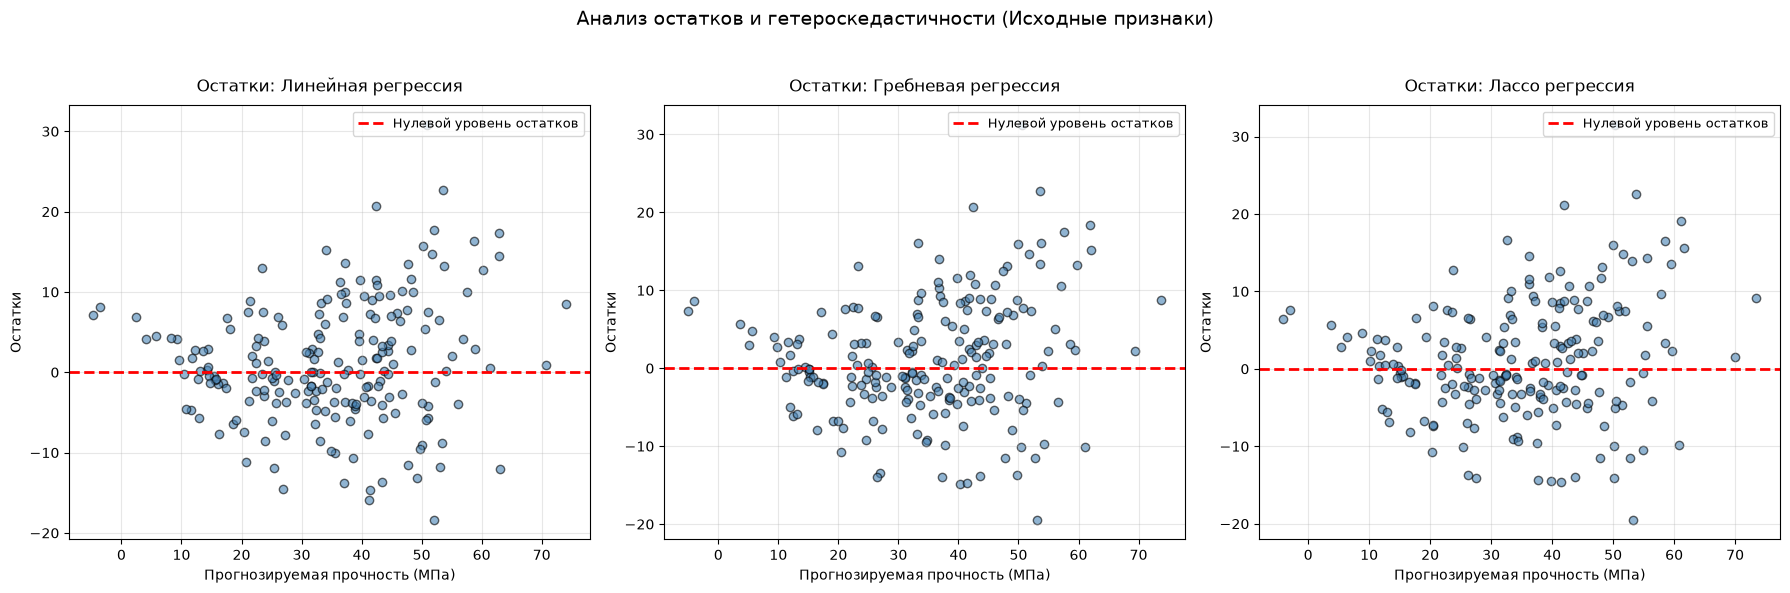

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (name, res) in zip(axes, residuals_orig.items()):
    ax.scatter(preds_orig[name], res, alpha=0.6, color='steelblue', edgecolor='k')
    ax.axhline(0, color='red', linestyle='--', linewidth=2, label='Нулевой уровень остатков')
        
    clean_name = name.split('(')[0].strip() 
    ax.set_title(f'Остатки: {clean_name}', fontsize=12, pad=10)
        
    ax.set_xlabel('Прогнозируемая прочность (МПа)', fontsize=10)
    ax.set_ylabel('Остатки', fontsize=10)
    ax.legend(loc='upper right', fontsize=9)
    ax.grid(True, alpha=0.3)

plt.suptitle("Анализ остатков и гетероскедастичности (Исходные признаки)", fontsize=14, y=0.98)

plt.tight_layout(rect=[0, 0, 1, 0.95])

Разброс остатков по оси ординат в целом сохраняет одинаковую ширину (примерно от -15 до +15 МПа) во всем диапазоне прогнозируемой прочности (от 10 до 60 МПа). Существенной гетероскедастичности не наблюдается.  

В области прогнозов 40–60 МПа наблюдаются единичные выбросы с положительной ошибкой до +20...+23 МПа и отрицательной до -18...-20 МПа. Эти аномалии связаны с физическими особенностями образцов бетона с экстремально высоким сроком выдержки (например, 365 дней) или нестандартными пропорциями добавок.


6. Результаты факторного анализа (PCA)
Главная компонента  Собственное значение (Lambda)  Доля дисперсии  Накопленная дисперсия
              ГК 1                         2.3067          0.2560                 0.2560
              ГК 2                         2.1844          0.2424                 0.4984
              ГК 3                         1.3702          0.1521                 0.6504
              ГК 4                         1.0838          0.1203                 0.7707
              ГК 5                         0.9532          0.1058                 0.8765
              ГК 6                         0.8059          0.0894                 0.9659
              ГК 7                         0.1972          0.0219                 0.9878
              ГК 8                         0.0795          0.0088                 0.9967
              ГК 9                         0.0302          0.0033                 1.0000


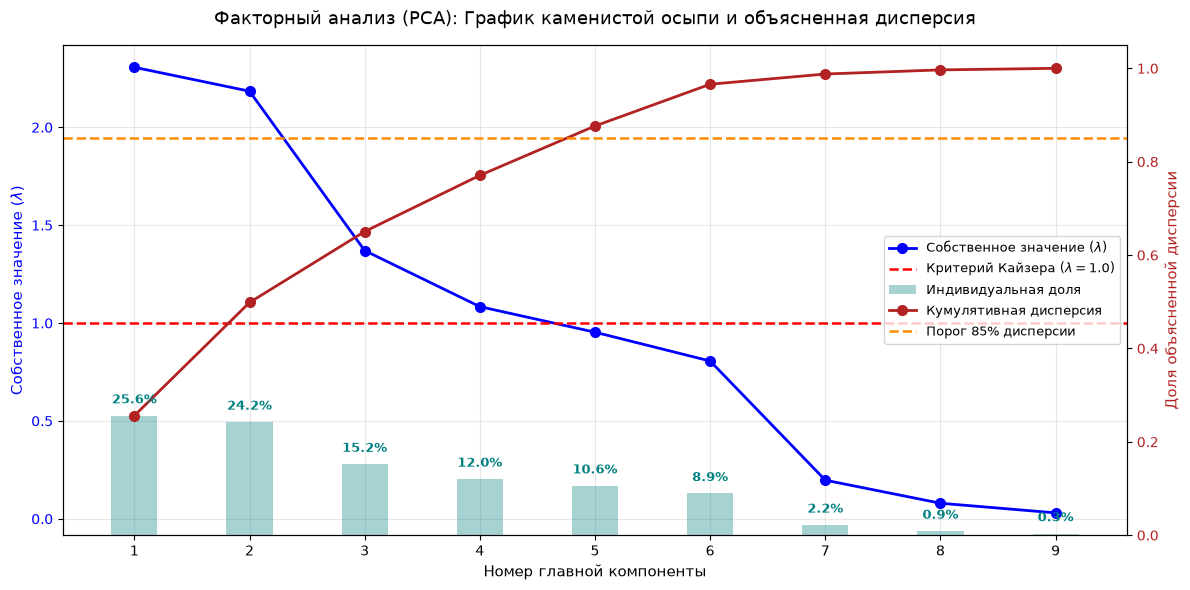

In [ ]:
from sklearn.decomposition import PCA

pca_full = PCA().fit(X_train_scaled)
eigenvalues = pca_full.explained_variance_
exp_var_ratio = pca_full.explained_variance_ratio_
cum_var = np.cumsum(exp_var_ratio)

pca_df = pd.DataFrame({
        'Главная компонента': [f'ГК {i+1}' for i in range(len(eigenvalues))],
        'Собственное значение (Lambda)': eigenvalues,
        'Доля дисперсии': exp_var_ratio,
        'Накопленная дисперсия': cum_var
})
print("\n6. Результаты факторного анализа (PCA)")
print(pca_df.round(4).to_string(index=False))

fig, ax1 = plt.subplots(figsize=(12, 6))

x_coords = range(1, len(eigenvalues) + 1)

line1 = ax1.plot(x_coords, eigenvalues, 'bo-', linewidth=2, markersize=7, label=r'Собственное значение ($\lambda$)')
line_kaiser = ax1.axhline(1.0, color='red', linestyle='--', linewidth=1.8, label=r'Критерий Кайзера ($\lambda = 1.0$)')
ax1.set_xlabel("Номер главной компоненты", fontsize=11)
ax1.set_ylabel(r"Собственное значение ($\lambda$)", color='blue', fontsize=11)
ax1.tick_params(axis='y', labelcolor='blue')
ax1.set_xticks(x_coords)
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()

bars = ax2.bar(x_coords, exp_var_ratio, alpha=0.35, color='teal', width=0.4, label='Индивидуальная доля дисперсии')

line2 = ax2.plot(x_coords, cum_var, 'o-', linewidth=2, markersize=7, color='firebrick', label='Кумулятивная дисперсия')
line_thresh = ax2.axhline(0.85, color='darkorange', linestyle='--', linewidth=1.8, label='Порог 85% дисперсии')

ax2.set_ylabel("Доля объясненной дисперсии", color='firebrick', fontsize=11)
ax2.tick_params(axis='y', labelcolor='firebrick')
ax2.set_ylim(0, 1.05)

for i, ratio in enumerate(exp_var_ratio):
    ax2.text(i + 1, ratio + 0.02, f"{ratio*100:.1f}%", ha='center', va='bottom', fontsize=9, color='teal', fontweight='bold')

handles = [line1[0], line_kaiser, bars, line2[0], line_thresh]
labels = [r'Собственное значение ($\lambda$)', r'Критерий Кайзера ($\lambda = 1.0$)', 
          'Индивидуальная доля', 'Кумулятивная дисперсия', 'Порог 85% дисперсии']

ax1.legend(handles, labels, loc='center right', fontsize=9.5)

plt.title("Факторный анализ (PCA): График каменистой осыпи и объясненная дисперсия", fontsize=13, pad=15)
plt.tight_layout()

Оценка по критерию Кайзера ($\lambda > 1.0$): Первые 4 главные компоненты (ГК 1 – ГК 4) имеют собственные значения больше 1. Это позволяет сократить размерность признакового пространства с 9 до 4 компонент без существенной потери информации.  
Первые две компоненты (ГК 1 и ГК 2) описывают почти половину всей информации — 49.84%.  
Для достижения информативности более 85% требуется 5 компонент.

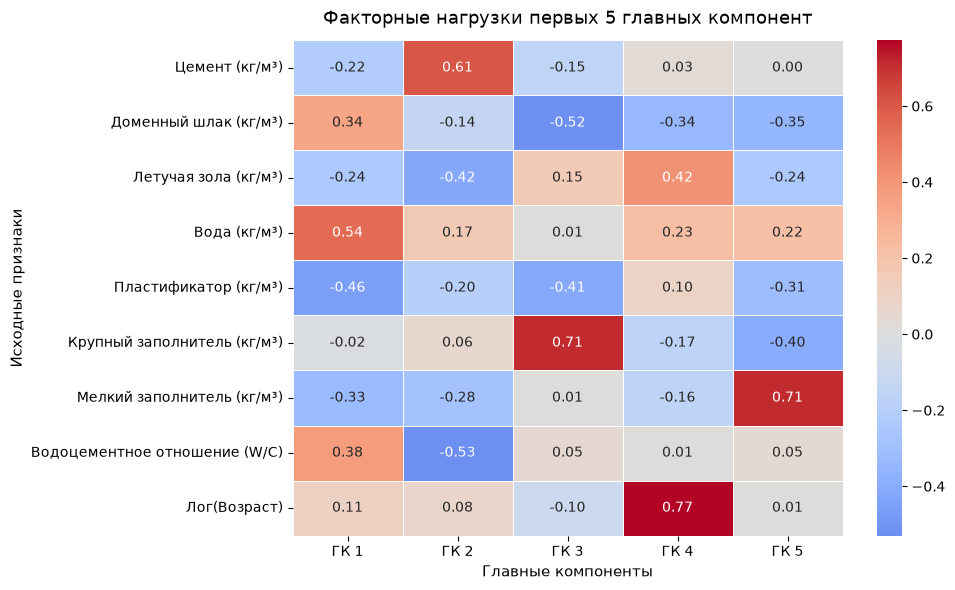

In [ ]:
k_opt = 5

pca_opt = PCA(n_components=k_opt).fit(X_train_scaled)
pca_feature_names = [f'ГК {i+1}' for i in range(k_opt)]

loadings = pd.DataFrame(
    pca_opt.components_.T,
    columns=pca_feature_names,
    index=feature_names
)

plt.figure(figsize=(10, 6))
sns.heatmap(
    loadings, 
    annot=True, 
    fmt=".2f", 
    cmap='coolwarm', 
    center=0, 
    linewidths=0.5
)

plt.title(f"Факторные нагрузки первых {k_opt} главных компонент", fontsize=13, pad=12)
plt.ylabel("Исходные признаки", fontsize=11)
plt.xlabel("Главные компоненты", fontsize=11)
plt.tight_layout()


ГК 1 (Водный баланс): Объединяет признаки, отвечающие за реологию и удобоукладываемость смеси. Противоположные знаки у Воды (+0.54) и Пластификатора (-0.46) подтверждают водоредуцирующий эффект пластификаторов в бетоне.  
ГК 2 ( Закон Абрамса): Сильная положительная корреляция с Цементом (0.61) и отрицательная с W/C отношением (-0.53) отражает классический закон прочности бетона: увеличение цемента при снижении водоцементного отношения повышает итоговую маркировку.  
ГК 3 и ГК 5 (Каркас бетона): Разделяют заполнители по фракциям — ГК 3 отвечает за крупную фракцию (щебень/гравий, 0.71), а ГК 5 за мелкую фракцию (песок, 0.71).  
ГК 4 (Фактор гидратации): Продемонстрировал определяющий вклад Лог(Возраста) (0.77). Это показывает, что PCA успешно выделил временную составляющую твердения бетона в отдельную ортогональную ось.


Вывод по ортогонализации:
Переход к 5 главным компонентам полностью устранил мультиколлинеарность между тесно связанными исходными параметрами (например, между цементом, водой, W/C и пластификатором), сохранив при этом 87.6% всей исходной информации.


7. Обучение моделей регрессии на главных компонентах
                               Модель (PCA)         R² (CV)  R² (Тест)  RMSE (МПа)  MAPE (%)
                 Линейная регрессия (на ГК) 0.6091 ± 0.0354     0.5699       11.33     31.44
Гребневая регрессия (Ridge на ГК, alpha=10) 0.6091 ± 0.0349     0.5694       11.33     31.47
   Лассо регрессия (Lasso на ГК, alpha=0.1) 0.6090 ± 0.0345     0.5692       11.34     31.44


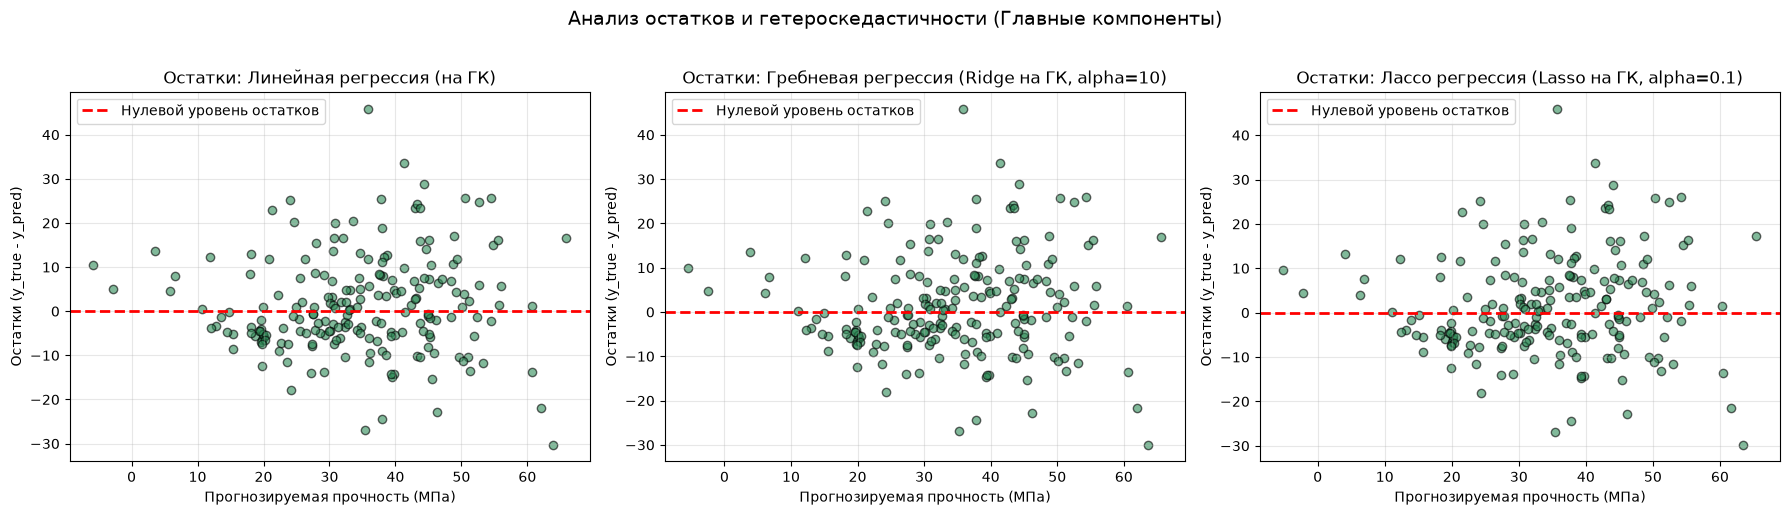

In [71]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error
from sklearn.model_selection import cross_val_score

X_train_pca = pd.DataFrame(pca_opt.transform(X_train_scaled), columns=pca_feature_names)
X_test_pca = pd.DataFrame(pca_opt.transform(X_test_scaled), columns=pca_feature_names)

models_pca = {
    'Линейная регрессия (на ГК)': LinearRegression(),
    'Гребневая регрессия (Ridge на ГК, alpha=10)': Ridge(alpha=10.0, random_state=42),
    'Лассо регрессия (Lasso на ГК, alpha=0.1)': Lasso(alpha=0.1, random_state=42)
}

results_pca = {}
preds_pca = {}
residuals_pca = {}

for name, model in models_pca.items():
    cv_scores = cross_val_score(model, X_train_pca, y_train, cv=kf, scoring='r2')
    model.fit(X_train_pca, y_train)
    y_pred = model.predict(X_test_pca)
        
    preds_pca[name] = y_pred
    residuals_pca[name] = y_test - y_pred

    results_pca[name] = {
        'R2_CV_mean': float(cv_scores.mean()),
        'R2_CV_std': float(cv_scores.std()),
        'R2_Test': float(r2_score(y_test, y_pred)),
        'RMSE_Test': float(np.sqrt(mean_squared_error(y_test, y_pred))),
        'MAPE_Test': float(mean_absolute_percentage_error(y_test, y_pred)),
        'intercept': float(model.intercept_),
        'coefficients': {col: float(coef) for col, coef in zip(pca_feature_names, model.coef_)}
    }

summary_pca_rows = []
for name, res in results_pca.items():
    summary_pca_rows.append({
        'Модель (PCA)': name,
        'R² (CV)': f"{res['R2_CV_mean']:.4f} ± {res['R2_CV_std']:.4f}",
        'R² (Тест)': round(res['R2_Test'], 4),
        'RMSE (МПа)': round(res['RMSE_Test'], 2),
        'MAPE (%)': round(res['MAPE_Test'] * 100, 2)
    })

summary_pca_df = pd.DataFrame(summary_pca_rows)

print("\n7. Обучение моделей регрессии на главных компонентах")
print(summary_pca_df.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, res) in zip(axes, residuals_pca.items()):
        ax.scatter(preds_pca[name], res, alpha=0.6, color='seagreen', edgecolor='k')
        ax.axhline(0, color='red', linestyle='--', linewidth=2, label='Нулевой уровень остатков')
        ax.set_title(f'Остатки: {name}')
        ax.set_xlabel('Прогнозируемая прочность (МПа)')
        ax.set_ylabel('Остатки (y_true - y_pred)')
        ax.legend()
        ax.grid(True, alpha=0.3)
    
plt.suptitle("Анализ остатков и гетероскедастичности (Главные компоненты)", fontsize=14, y=1.02)
plt.tight_layout()

Линейная, Ridge и Lasso регрессии показали практически одинаковую точность ($R^2_{test} \approx 0.57$, $RMSE \approx 11.33$ МПа). Это подтверждает, что ортогонализация признаков с помощью PCA нивелировала необходимость в дополнительной $L_1/L_2$ регуляризации.
Стабильность метрик между CV ($0.6091$) и тест-выборкой ($0.5699$) указывает на отсутствие переобучения.  
Анализ остатков:  
* Разброс ошибок центрирован относительно нуля.
* Признаки гетероскедастичности проявляются в зоне высокой прочности ($>40$ МПа).
* Выявлена группа выбросов с ошибкой прогноза $>30$ МПа.


8. Итоговая сравнительная таблица всех моделей
             Модель Пространство признаков  R² (CV)  R² (Тест)  RMSE (Тест, МПа)  MAPE (Тест, %)
 Линейная регрессия           Исходные (9)   0.8033     0.8033            7.6610         20.9229
Гребневая регрессия           Исходные (9)   0.8003     0.8005            7.7155         21.2348
    Лассо регрессия           Исходные (9)   0.7991     0.7989            7.7448         21.1312
 Линейная регрессия             PCA (5 ГК)   0.6091     0.5699           11.3274         31.4443
Гребневая регрессия             PCA (5 ГК)   0.6091     0.5694           11.3335         31.4708
    Лассо регрессия             PCA (5 ГК)   0.6090     0.5692           11.3364         31.4399


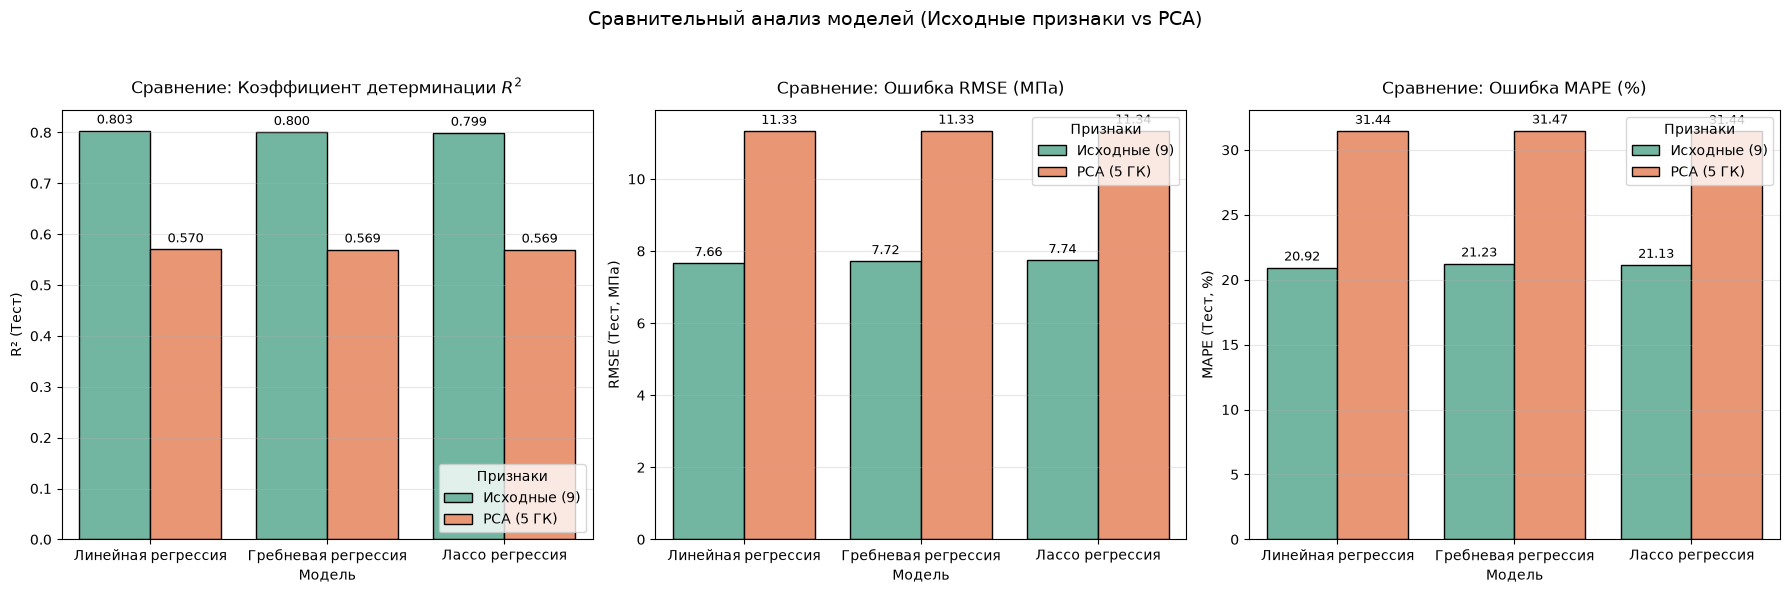

In [80]:
summary_rows = []

for name, res in results_orig.items():
    short_name = name.split('(')[0].strip()
    summary_rows.append({
        'Модель': short_name,
        'Пространство признаков': f'Исходные ({len(feature_names)})',
        'R² (CV)': res['R2_CV_mean'],
        'R² (Тест)': res['R2_Test'],
        'RMSE (Тест, МПа)': res['RMSE_Test'],
        'MAPE (Тест, %)': res['MAPE_Test'] * 100
    })

for name, res in results_pca.items():
    short_name = name.split('(')[0].strip()
    summary_rows.append({
        'Модель': short_name,
        'Пространство признаков': f'PCA ({k_opt} ГК)',
        'R² (CV)': res['R2_CV_mean'],
        'R² (Тест)': res['R2_Test'],
        'RMSE (Тест, МПа)': res['RMSE_Test'],
        'MAPE (Тест, %)': res['MAPE_Test'] * 100
    })

summary_df = pd.DataFrame(summary_rows)
summary_df_sorted = summary_df.sort_values(by='R² (Тест)', ascending=False).reset_index(drop=True)

print("\n8. Итоговая сравнительная таблица всех моделей")
print(summary_df_sorted.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

metrics = [
    ('R² (Тест)', 'Коэффициент детерминации $R^2$', '.3f'),
    ('RMSE (Тест, МПа)', 'Ошибка RMSE (МПа)', '.2f'),
    ('MAPE (Тест, %)', 'Ошибка MAPE (%)', '.2f')
]

for ax, (metric, title, fmt) in zip(axes, metrics):
    sns.barplot(
        data=summary_df, 
        x='Модель', 
        y=metric, 
        hue='Пространство признаков', 
        ax=ax, 
        palette='Set2', 
        edgecolor='black'
    )
    
    ax.set_title(f"Сравнение: {title}", fontsize=12, pad=12)
    ax.set_xlabel("Модель", fontsize=10)
    ax.set_ylabel(metric, fontsize=10)
    ax.grid(True, axis='y', alpha=0.3)

    loc_legend = 'lower right' if 'R²' in metric else 'upper right'
    ax.legend(title='Признаки', loc=loc_legend)

    for p in ax.patches:
        height = p.get_height()
        if not np.isnan(height) and height != 0:
            ax.annotate(
                f'{height:{fmt}}',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom',
                fontsize=9, xytext=(0, 3),
                textcoords='offset points'
            )

plt.suptitle("Сравнительный анализ моделей (Исходные признаки vs PCA)", fontsize=14, y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.95])

Модели, обученные на полном пространстве исходных признаков (9 переменных), существенно превосходят модели на базе 5 главных компонент (PCA) по всем метрикам.  
Наивысшую точность продемонстрировала Обычная линейная регрессия на исходных признаках.  
Сокращение признакового пространства с 9 до 5 компонент привело к утере ~23% объясненной дисперсии тестовой выборки (снижение $R^2$ с $0.8033$ до $0.5699$) и росту средней ошибки на ~3.66 МПа.  
Если приоритетом является максимальная точность прогноза прочности бетона, следует использовать исходный набор из 9 признаков. Если ключевым требованием является полная независимость факторов и интерпретируемость главных осей, допускается использование моделей на 5 ГК при согласии на допустимую погрешность $\approx 31.4\%$.

In [82]:
weights_df = pd.DataFrame({
    'Признак': feature_names,
    'Linear': models_orig['Линейная регрессия (OLS)'].coef_,
    'Ridge': models_orig['Гребневая регрессия (Ridge, alpha=10)'].coef_,
    'Lasso': models_orig['Лассо регрессия (Lasso, alpha=0.1)'].coef_
})

print("\n9. Веса моделей на стандартизированных признаках")
print(weights_df.round(3).to_string(index=False))


9. Веса моделей на стандартизированных признаках
                      Признак  Linear  Ridge  Lasso
               Цемент (кг/м³)  11.908  9.708  9.357
        Доменный шлак (кг/м³)   9.665  7.936  7.094
         Летучая зола (кг/м³)   5.980  4.428  3.782
                 Вода (кг/м³)  -2.109 -3.140 -4.069
        Пластификатор (кг/м³)   0.789  0.858  0.565
  Крупный заполнитель (кг/м³)   1.977  0.760  0.001
   Мелкий заполнитель (кг/м³)   2.738  1.152  0.273
Водоцементное отношение (W/C)  -1.955 -2.451 -1.972
                 Лог(Возраст)   9.945  9.715  9.701


Анализ весов регрессионных моделей:  
Наиболее значимые факторы: Цемент (+11.91), Лог(Возраст) (+9.95) и Доменный шлак (+9.67). Их увеличение гарантирует наибольший прирост прочности бетона.  
Ограничивающие факторы: Вода и Водоцементное отношение (W/C) демонстрируют отрицательные коэффициенты във всех моделях, что физически оправдано (избыток воды снижает плотность структуры).  
Эффект регуляризации: Модель Lasso практически обнулила коэффициент при Крупном заполнителе (0.001), указав на его второстепенную роль при наличии других фракций в наборе данных.

## Заключение

В ходе выполнения лабораторной работы были изучены теоретические основы и практические аспекты построения моделей линейной регрессии, а также применения метода главных компонент (PCA) для анализа и снижения размерности данных.  


В процессе работы проведена первичная предобработка данных, построена корреляционная матрица и выполнен анализ VIF (фактора инфляции дисперсии), который выявил наличие мультиколлинеарности между несколькими непрерывными признаками. Для оценки качества прогнозирования были построены и обучены модели классической линейной регрессии (OLS), а также регуляризованные модели Ridge ($L_2$) и Lasso ($L_1$). Наивысшую точность продемонстрировала обычная линейная регрессия, обученная на полном пространстве из 9 исходных стандартизированных признаков, достигшая коэффициента детерминации $R^2 = 0.8033$, ошибки $\text{RMSE} = 7.66$ и $\text{MAPE} = 20.92\%$. Анализ весов показал, что регуляризация Lasso успешно справляется с отбором факторов, практически обнуляя коэффициенты наименее информативных переменных.  


С целью устранения мультиколлинеарности и понижения размерности данных был применен метод главных компонент. На основе критерия Кайзера и анализа доли накопленной дисперсии было отобрано 5 главных компонент, суммарно объясняющих порядка $87.65\%$ исходной вариативности. Повторное обучение моделей регрессии на полученных главных компонентах позволило полностью избавиться от линейной зависимости между признаками, однако привело к снижению предсказательной способности моделей ($R^2 \approx 0.5699$, $\text{RMSE} \approx 11.33$) за счет утери части информации.  


Сравнительный анализ показал, что выбор между исходным пространством признаков и главными компонентами зависит от прикладных задач: использование исходных признаков предпочтительно для достижения максимальной точности прогнозирования, тогда как переход к главным компонентам оправдан при необходимости устранения мультиколлинеарности и перехода к взаимно ортогональным факторам. Поставленные цели и задачи лабораторной работы выполнены в полном объеме.

## Список источников
1. Документация библиотеки Scikit-Learn: https://scikit-learn.org/stable/modules/linear_model.html
2. Документация библиотеки Statsmodels: https://www.statsmodels.org/
3. Системы искусственного интеллекта: учебное пособие / А. А. Алетдинова, М. Г. Гриф. – Новосибирск: Изд-во НГТУ, 2023. – 76 с.
4. Concrete Compressive Strength Data Set [Electronic resource] // UCI Machine Learning Repository. — URL: https://archive.ics.uci.edu/ml/datasets/Concrete+Compressive+Strength (дата обращения: 02.10.2026).
5. Флач, П. Машинное обучение. Наука и искусство построения алгоритмов с помощью данных / П. Флач ; пер. с англ. А. А. Слинкина. — Москва : ДМК Пресс, 2015. — 400 с.